# Anomalies du S&P 500 autour des décisions de politique monétaire de la Fed

**Question de recherche.** Dans quelle mesure les anomalies détectées sur le S&P 500 par Isolation Forest se concentrent-elles autour des décisions du FOMC, et le régime de taux — resserrement, assouplissement ou statu quo — modifie-t-il leur fréquence et leur nature ?

Ce notebook est exécutable sur Google Colab. Il télécharge les données au moment de l'exécution, construit des variables de rendement et de volatilité, applique Isolation Forest, aligne les observations sur les réunions du FOMC et compare les fenêtres d'événement à des jours de contrôle.

> Une anomalie statistique n'est pas nécessairement une erreur de marché ni un effet causal de la Fed. L'analyse identifie une coïncidence temporelle et des différences de distribution, pas une causalité à elle seule.

## Méthode et hypothèses

- **Anomalie :** Isolation Forest est appliqué au rendement à 1 jour, rendement à 5 jours, volatilité réalisée à 21 jours, variation absolue et drawdown à 63 jours. `contamination=2%` définit la part approximative d'observations atypiques.
- **Événement monétaire :** une date FOMC correspond au jour du communiqué ; la fenêtre principale couvre 5 séances avant à 5 séances après.
- **Régime de taux :** variation passée du taux effectif des fed funds sur environ 3 mois, sans utiliser d'information future. Plus de +25 points de base = resserrement, moins de -25 points de base = assouplissement, sinon statu quo.
- **Tests :** fréquence d'anomalies, score, rendement et volatilité ; test exact de Fisher et test de permutation.

In [3]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn scipy requests jinja2

In [4]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from scipy.stats import fisher_exact
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (13, 6)
RANDOM_STATE = 42

## Données

Les séries sont téléchargées depuis FRED au format CSV. `SP500` est un indice quotidien à la clôture ; `DFF` est le taux effectif quotidien des fed funds.

In [5]:
FRED_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}&cosd=2015-01-01'

def load_fred(series):
    df = pd.read_csv(FRED_URL.format(series=series))
    df['observation_date'] = pd.to_datetime(df['observation_date'])
    df = df.rename(columns={'observation_date': 'date', series: series})
    df[series] = pd.to_numeric(df[series], errors='coerce')
    return df.set_index('date').sort_index()

sp500 = load_fred('SP500')
dff = load_fred('DFF')
data = sp500.join(dff, how='outer').sort_index()
data = data.loc[data.index >= '2015-01-01']
data['DFF'] = data['DFF'].ffill()
data = data.dropna(subset=['SP500'])
print(f"Période : {data.index.min().date()} à {data.index.max().date()} | observations : {len(data):,}")
display(data.tail())

Période : 2025-11-17 à 2026-11-16 | observations : 251


,SP500,DFF
date,,
2026-11-10,7520.93,3.88
2026-11-11,7619.38,3.88
2026-11-12,7592.40,3.88
2026-11-13,7561.67,3.88
2026-11-16,7416.59,3.88


## Dates des décisions FOMC

Dates de publication des décisions FOMC, couvrant 2016–2026. Les dates futures ou absentes des données sont ignorées automatiquement.

In [6]:
fomc_dates = [
'2016-01-27','2016-03-16','2016-04-27','2016-06-15','2016-07-27','2016-09-21','2016-11-02','2016-12-14',
'2017-02-01','2017-03-15','2017-05-03','2017-06-14','2017-07-26','2017-09-20','2017-11-01','2017-12-13',
'2018-01-31','2018-03-21','2018-05-02','2018-06-13','2018-08-01','2018-09-26','2018-11-08','2018-12-19',
'2019-01-30','2019-03-20','2019-05-01','2019-06-19','2019-07-31','2019-09-18','2019-10-30','2019-12-11',
'2020-01-29','2020-03-03','2020-03-15','2020-04-29','2020-06-10','2020-07-29','2020-09-16','2020-11-05','2020-12-16',
'2021-01-27','2021-03-17','2021-04-28','2021-06-16','2021-07-28','2021-09-22','2021-11-03','2021-12-15',
'2022-01-26','2022-03-16','2022-05-04','2022-06-15','2022-07-27','2022-09-21','2022-11-02','2022-12-14',
'2023-02-01','2023-03-22','2023-05-03','2023-06-14','2023-07-26','2023-09-20','2023-11-01','2023-12-13',
'2024-01-31','2024-03-20','2024-05-01','2024-06-12','2024-07-31','2024-09-18','2024-11-07','2024-12-18',
'2025-01-29','2025-03-19','2025-05-07','2025-06-18','2025-07-30','2025-09-17','2025-10-29','2025-12-10',
'2026-01-28','2026-03-18','2026-04-29','2026-06-17','2026-07-29','2026-09-16','2026-10-28'
]
fomc = pd.DataFrame({'fomc_date': pd.to_datetime(fomc_dates)})
fomc = fomc[(fomc.fomc_date >= data.index.min()) & (fomc.fomc_date <= data.index.max())]
fomc_idx = pd.DatetimeIndex(fomc.fomc_date)
print('Décisions retenues :', len(fomc))

Décisions retenues : 8


## Variables financières et Isolation Forest

In [7]:
df = data.copy()
df['return_1d'] = df.SP500.pct_change()
df['return_5d'] = df.SP500.pct_change(5)
df['abs_return_1d'] = df.return_1d.abs()
df['vol_21d'] = df.return_1d.rolling(21).std() * np.sqrt(252)
df['drawdown_63d'] = df.SP500 / df.SP500.rolling(63).max() - 1
df['rate_change_63d'] = df.DFF - df.DFF.shift(63)
features = ['return_1d','return_5d','abs_return_1d','vol_21d','drawdown_63d']
model_df = df.dropna(subset=features + ['DFF','rate_change_63d']).copy()
X = StandardScaler().fit_transform(model_df[features])
iso = IsolationForest(n_estimators=500, contamination=0.02, random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(X)
model_df['is_anomaly'] = iso.predict(X).eq(-1) if isinstance(iso.predict(X), pd.Series) else (iso.predict(X) == -1)
model_df['anomaly_score'] = -iso.score_samples(X)
print(f"Observations modélisées : {len(model_df):,}")
print(f"Anomalies : {model_df.is_anomaly.sum():,} ({model_df.is_anomaly.mean():.2%})")
display(model_df[features + ['is_anomaly','anomaly_score']].sort_values('anomaly_score', ascending=False).head(10))

Observations modélisées : 188
Anomalies : 4 (2.13%)


,return_1d,return_5d,abs_return_1d,vol_21d,drawdown_63d,is_anomaly,anomaly_score
date,,,,,,,
2026-11-05,-0.043557,-0.047492,0.043557,0.194483,-0.059497,True,0.766851
2026-03-31,0.029131,-0.004248,0.029131,0.185376,-0.064494,True,0.671341
2026-04-08,0.025081,0.038951,0.025081,0.198521,-0.028056,True,0.647663
2026-11-16,-0.019186,-0.017662,0.019186,0.223072,-0.051457,True,0.623918
2026-03-30,-0.003946,-0.036055,0.003946,0.146326,-0.090975,False,0.620860
2026-06-05,-0.026445,-0.025900,0.026445,0.131339,-0.029704,False,0.616593
2026-11-09,0.023463,0.001132,0.023463,0.213373,-0.034402,False,0.610407
2026-03-27,-0.016722,-0.021153,0.016722,0.146337,-0.087374,False,0.587119
2026-08-04,0.017896,0.041425,0.017896,0.143111,0.000000,False,0.585278


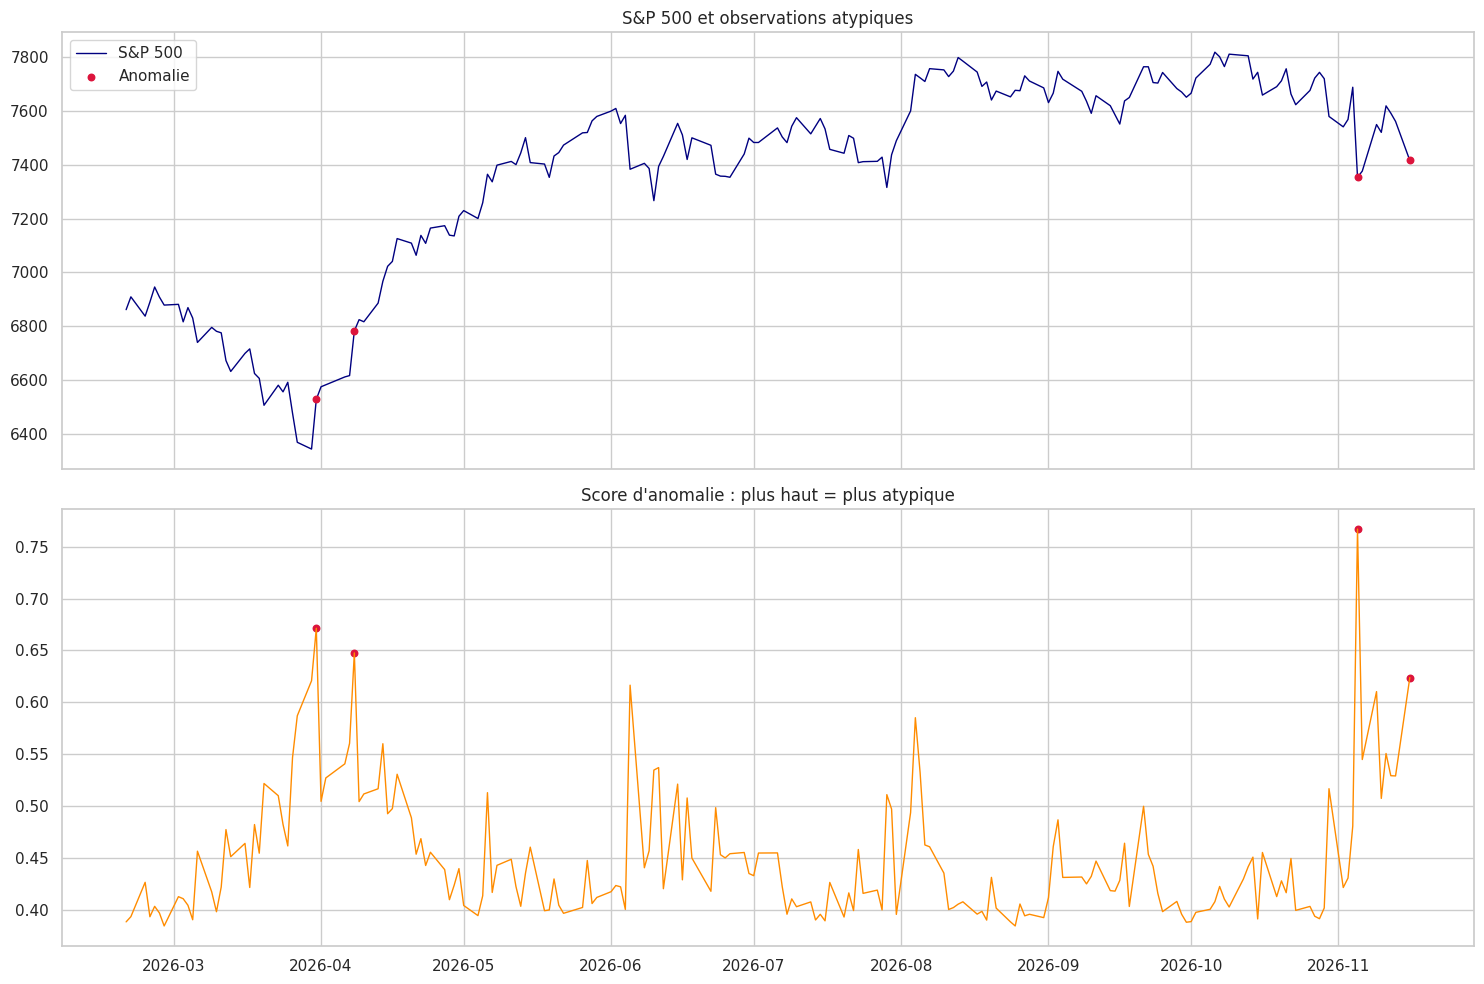

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
anom = model_df[model_df.is_anomaly]
axes[0].plot(model_df.index, model_df.SP500, color='navy', lw=1, label='S&P 500')
axes[0].scatter(anom.index, anom.SP500, color='crimson', s=22, label='Anomalie', zorder=3)
axes[0].set_title('S&P 500 et observations atypiques')
axes[0].legend()
axes[1].plot(model_df.index, model_df.anomaly_score, color='darkorange', lw=1)
axes[1].scatter(anom.index, anom.anomaly_score, color='crimson', s=22)
axes[1].set_title("Score d'anomalie : plus haut = plus atypique")
plt.tight_layout(); plt.show()

## Régimes de taux et fenêtres FOMC

In [9]:
THRESHOLD_PP = 0.25
def classify_regime(x):
    if x > THRESHOLD_PP: return 'Resserrement'
    if x < -THRESHOLD_PP: return 'Assouplissement'
    return 'Statu quo'
model_df['regime'] = model_df.rate_change_63d.apply(classify_regime)
# Fenêtre de +/- 5 séances, centrée sur la première séance disponible à la date de décision
model_df['event_window_5d'] = False
positions = model_df.index
for e in fomc_idx:
    center = positions.get_indexer([e], method='bfill')[0]
    lo, hi = max(0, center-5), min(len(model_df)-1, center+5)
    model_df.iloc[lo:hi+1, model_df.columns.get_loc('event_window_5d')] = True
print('Répartition des régimes :')
display(model_df.regime.value_counts(normalize=True).rename('part').to_frame())

Répartition des régimes :


,part
regime,
Statu quo,0.978723
Resserrement,0.021277


## Concentration autour des décisions

In [10]:
event_summary = (model_df.groupby('event_window_5d').agg(
    n=('is_anomaly','size'), anomalies=('is_anomaly','sum'), anomaly_rate=('is_anomaly','mean'),
    mean_score=('anomaly_score','mean'), mean_abs_return=('abs_return_1d','mean'),
    negative_return_share=('return_1d', lambda s: (s < 0).mean()))
    .rename(index={False:'Contrôle hors fenêtre', True:'Fenêtre FOMC ±5 séances'}))
display(event_summary.style.format({'anomaly_rate':'{:.2%}','mean_score':'{:.3f}','mean_abs_return':'{:.2%}','negative_return_share':'{:.2%}'}))
contingency = pd.crosstab(model_df.event_window_5d, model_df.is_anomaly).reindex(index=[False,True], columns=[False,True], fill_value=0)
odds_ratio, fisher_p = fisher_exact(contingency.values)
print('Table 2x2 (lignes hors fenêtre/fenêtre, colonnes normal/anomalie)'); display(contingency)
print(f'Odds ratio Fisher = {odds_ratio:.3f} ; p-value = {fisher_p:.4f}')

,n,anomalies,anomaly_rate,mean_score,mean_abs_return,negative_return_share
event_window_5d,,,,,,
Contrôle hors fenêtre,116,4,3.45%,0.450,0.63%,48.28%
Fenêtre FOMC ±5 séances,72,0,0.00%,0.448,0.75%,51.39%


Table 2x2 (lignes hors fenêtre/fenêtre, colonnes normal/anomalie)


is_anomaly,False,True
event_window_5d,,
False,112,4
True,72,0


Odds ratio Fisher = 0.000 ; p-value = 0.2997


Différence observée FOMC - contrôle : -3.45%
p-value par permutation : 0.1592


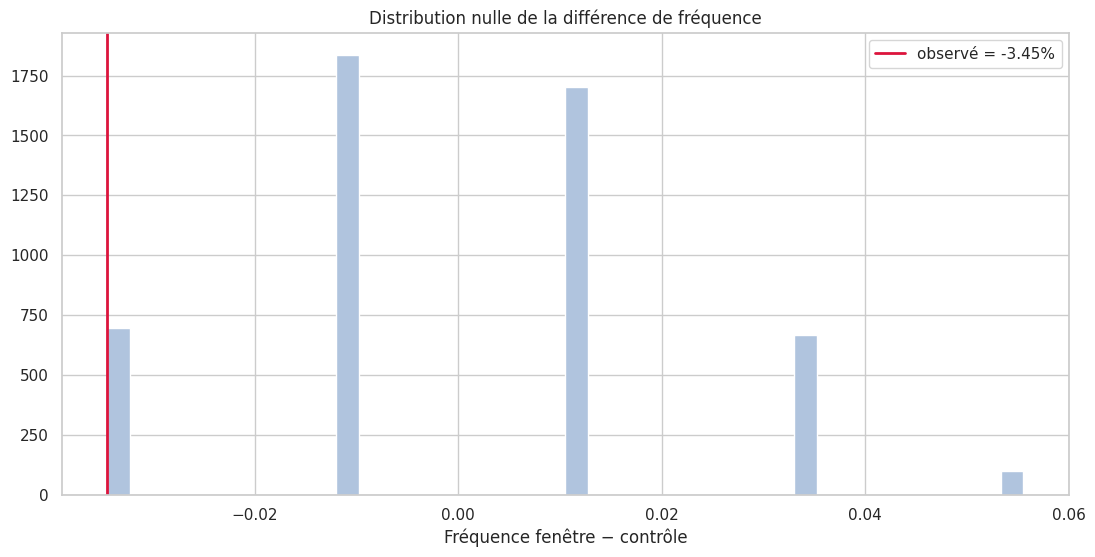

In [11]:
# Test de permutation de la différence de fréquence
observed_diff = (model_df.loc[model_df.event_window_5d,'is_anomaly'].mean() - model_df.loc[~model_df.event_window_5d,'is_anomaly'].mean())
rng = np.random.default_rng(RANDOM_STATE)
labels = model_df.is_anomaly.to_numpy(); n_event = int(model_df.event_window_5d.sum()); n_total = len(model_df)
permuted = []
for _ in range(5000):
    idx = rng.choice(n_total, size=n_event, replace=False); mask = np.zeros(n_total, dtype=bool); mask[idx] = True
    permuted.append(labels[mask].mean() - labels[~mask].mean())
permuted = np.array(permuted); perm_p = (np.abs(permuted) >= abs(observed_diff)).mean()
print(f'Différence observée FOMC - contrôle : {observed_diff:.2%}')
print(f'p-value par permutation : {perm_p:.4f}')
plt.hist(permuted, bins=40, color='lightsteelblue', edgecolor='white')
plt.axvline(observed_diff, color='crimson', lw=2, label=f'observé = {observed_diff:.2%}')
plt.title('Distribution nulle de la différence de fréquence'); plt.xlabel('Fréquence fenêtre − contrôle'); plt.legend(); plt.show()

## Le régime de taux modifie-t-il la fréquence et la nature des anomalies ?

,n,anomalies,anomaly_rate,mean_score,mean_abs_return,median_abs_return,mean_vol_21d,negative_return_share
regime,,,,,,,,
Statu quo,184,4,2.17%,0.450,0.68%,0.52%,13.18%,49.46%
Resserrement,4,0,0.00%,0.411,0.46%,0.52%,10.22%,50.00%


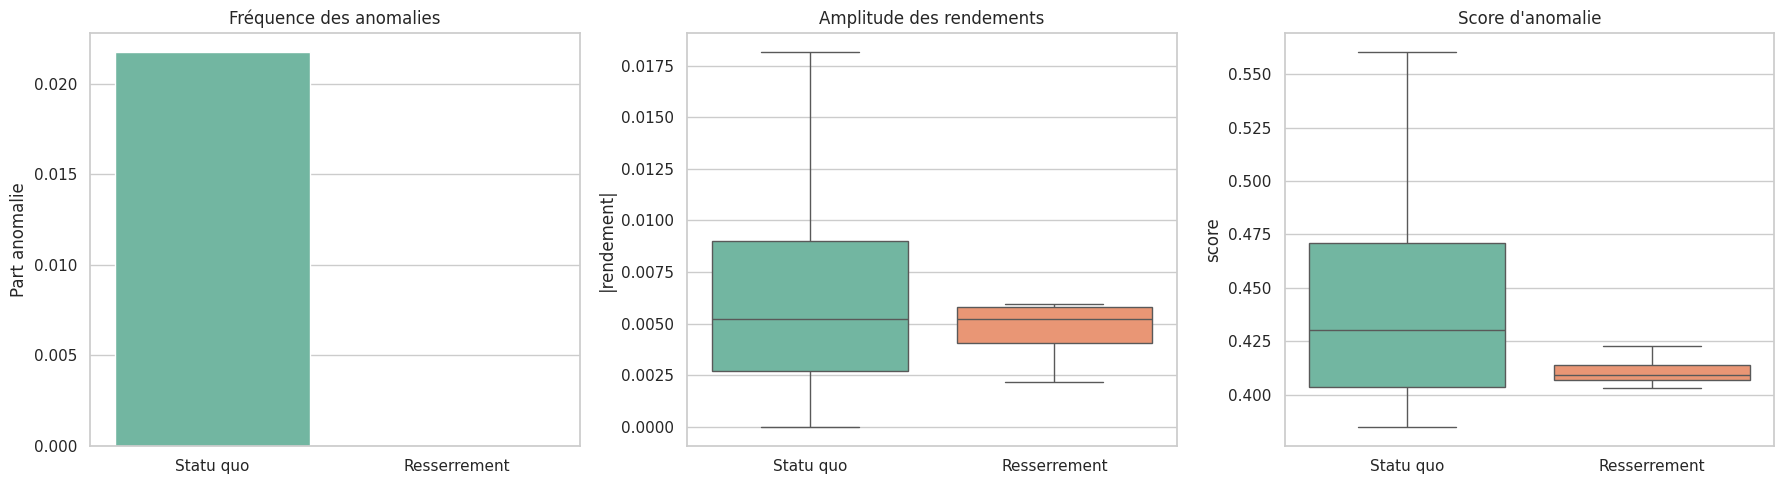

In [12]:
regime_summary = (model_df.groupby('regime').agg(
    n=('is_anomaly','size'), anomalies=('is_anomaly','sum'), anomaly_rate=('is_anomaly','mean'),
    mean_score=('anomaly_score','mean'), mean_abs_return=('abs_return_1d','mean'),
    median_abs_return=('abs_return_1d','median'), mean_vol_21d=('vol_21d','mean'),
    negative_return_share=('return_1d', lambda s: (s < 0).mean())).sort_values('anomaly_rate', ascending=False))
display(regime_summary.style.format({'anomaly_rate':'{:.2%}','mean_score':'{:.3f}','mean_abs_return':'{:.2%}','median_abs_return':'{:.2%}','mean_vol_21d':'{:.2%}','negative_return_share':'{:.2%}'}))
fig, axes = plt.subplots(1,3,figsize=(18,5))
sns.barplot(data=model_df, x='regime', y='is_anomaly', estimator='mean', errorbar=None, ax=axes[0], palette='Set2'); axes[0].set_title('Fréquence des anomalies'); axes[0].set_ylabel('Part anomalie'); axes[0].set_xlabel('')
sns.boxplot(data=model_df, x='regime', y='abs_return_1d', showfliers=False, ax=axes[1], palette='Set2'); axes[1].set_title('Amplitude des rendements'); axes[1].set_ylabel('|rendement|'); axes[1].set_xlabel('')
sns.boxplot(data=model_df, x='regime', y='anomaly_score', showfliers=False, ax=axes[2], palette='Set2'); axes[2].set_title("Score d'anomalie"); axes[2].set_ylabel('score'); axes[2].set_xlabel('')
plt.tight_layout(); plt.show()

,regime,event_window_5d,n,anomalies,anomaly_rate,mean_abs_return
0,Resserrement,False,4,0,0.00%,0.46%
1,Statu quo,False,112,4,3.57%,0.64%
2,Statu quo,True,72,0,0.00%,0.75%


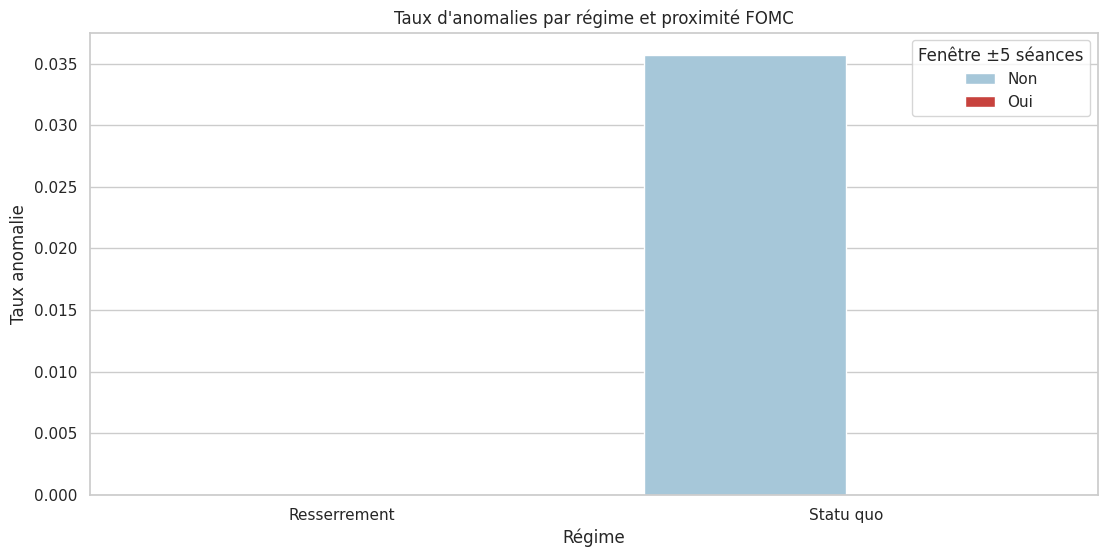

In [13]:
cross = (model_df.groupby(['regime','event_window_5d']).agg(n=('is_anomaly','size'), anomalies=('is_anomaly','sum'), anomaly_rate=('is_anomaly','mean'), mean_abs_return=('abs_return_1d','mean')).reset_index())
display(cross.style.format({'anomaly_rate':'{:.2%}','mean_abs_return':'{:.2%}'}))
sns.barplot(data=cross, x='regime', y='anomaly_rate', hue='event_window_5d', errorbar=None, palette=['#9ecae1','#de2d26'])
plt.title("Taux d'anomalies par régime et proximité FOMC"); plt.ylabel('Taux anomalie'); plt.xlabel('Régime'); plt.legend(title='Fenêtre ±5 séances', labels=['Non','Oui']); plt.show()

## Lecture synthétique et limites

In [14]:
event_rate = event_summary.loc['Fenêtre FOMC ±5 séances','anomaly_rate']
control_rate = event_summary.loc['Contrôle hors fenêtre','anomaly_rate']
regime_top = regime_summary.anomaly_rate.idxmax(); regime_bottom = regime_summary.anomaly_rate.idxmin()
print('Lecture synthétique')
print('-'*80)
print(f"1) Fenêtre FOMC : {event_rate:.2%} d'anomalies contre {control_rate:.2%} hors fenêtre.")
print(f"   Différence : {event_rate-control_rate:+.2%} ; p-value Fisher : {fisher_p:.4f}.")
print(f"2) Régime le plus atypique : {regime_top} ({regime_summary.loc[regime_top,'anomaly_rate']:.2%}).")
print(f"   Régime le moins atypique : {regime_bottom} ({regime_summary.loc[regime_bottom,'anomaly_rate']:.2%}).")
print("3) Une fréquence plus élevée autour du FOMC indique une concentration temporelle, mais ne prouve pas une causalité.")
print("4) Robustesse recommandée : tester plusieurs contaminations, fenêtres, sous-périodes et surprises de taux.")

Lecture synthétique
--------------------------------------------------------------------------------
1) Fenêtre FOMC : 0.00% d'anomalies contre 3.45% hors fenêtre.
   Différence : -3.45% ; p-value Fisher : 0.2997.
2) Régime le plus atypique : Statu quo (2.17%).
   Régime le moins atypique : Resserrement (0.00%).
3) Une fréquence plus élevée autour du FOMC indique une concentration temporelle, mais ne prouve pas une causalité.
4) Robustesse recommandée : tester plusieurs contaminations, fenêtres, sous-périodes et surprises de taux.


## Sources

- Federal Reserve, [Meeting calendars and information](https://www.federalreserve.gov/monetarypolicy/fomccalendars.htm).
- Federal Reserve Bank of St. Louis, [S&P 500 (SP500)](https://fred.stlouisfed.org/series/SP500).
- Federal Reserve Bank of St. Louis, [Federal Funds Effective Rate (DFF)](https://fred.stlouisfed.org/series/DFF).

**Limites.** Les données FRED peuvent être révisées et l'historique quotidien du S&P 500 diffusé peut être limité. Les dates FOMC sont des dates d'annonce ; les marchés peuvent anticiper la décision. DFF mesure le taux effectif réalisé, pas la surprise par rapport aux anticipations. Une identification causale demanderait une mesure de surprise monétaire et une étude d'événement plus stricte.